Order of Events
1. Planning
    - Get coordinates of environment (from Vision)
    - Compute visibility graph and path (from Global Nav)
3. Motion
    - Start following path
    - Continuously correct route with Kalman filter (from Kalman)
4. Local Navigation
    - Add extra obstacle in path
    - Avoid obstacle (from Local Nav)
5. Success
    - Reach Goal

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw
import math
from VisibilityGraph import *
from kalman_filter import *
from Vision import *

In [11]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [3]:
# UNCOMMENT TO TEST HARDCODED MAP

# Global Nav Variables as standin for input from Vision
# ob1 = [(176, 206), (215, 217), (194, 294), (155, 283)]
# ob2 = [(522, 440), (562, 440), (562, 520), (522, 520)]
# ob3 = [(870, 267), (909, 256), (930, 333), (891, 344)]

# raw_obstacles = (ob1, ob2, ob3)

In [2]:
def wrap_angle(angle):
    """Wrap angle to [-pi, pi]."""
    return math.atan2(math.sin(angle), math.cos(angle))

def compute_heading(a, b, prev_heading):
    dx = b[0] - a[0]
    dy = b[1] - a[1]

    distance = math.hypot(dx, dy)
    abs_heading = math.atan2(dy, dx)          # absolute heading of this segment
    turn = wrap_angle(abs_heading - prev_heading)  # signed turn needed from current heading

    return distance, turn, abs_heading

In [3]:
SPEED_TO_MM_S = 0.335   
WHEEL_BASE = 95.0

async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def forward(v, d): # [mm/s, mm]
    T = d/v
    thymio_v = v/SPEED_TO_MM_S
    
    try:
        await set_speed(thymio_v, thymio_v)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)
        
async def turn(v, theta): # [rad/s, rad]

    arc = abs(theta) * WHEEL_BASE / 2 
    T = arc / v                          
    thymio_v =  abs(v) / SPEED_TO_MM_S         
    direction = 1 if theta > 0 else -1
    try:
        await set_speed(-direction * thymio_v, direction * thymio_v)
        await client.sleep(T)
    finally:
        await set_speed(0, 0)

RuntimeError: Missing calibration markers: [1, 0]

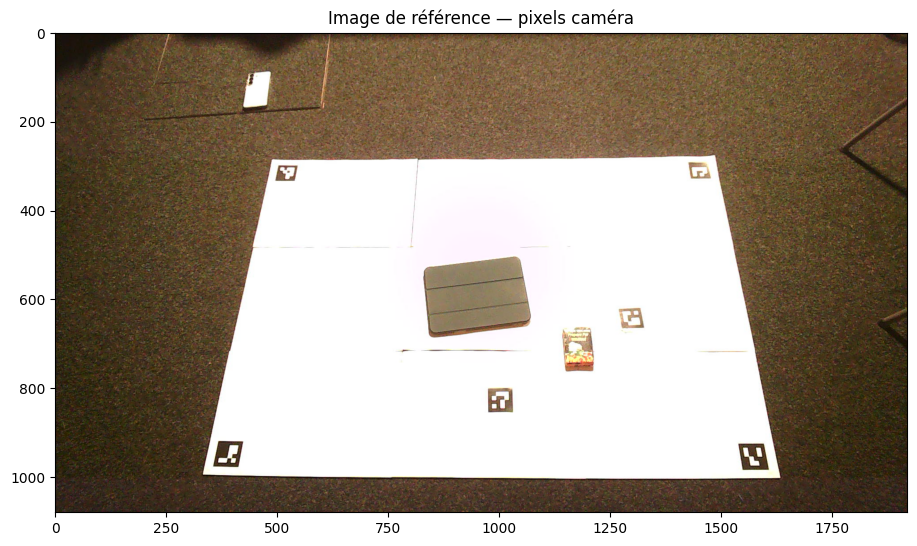

In [5]:
initialize_vision(True)

[0, 3, 4, 1] [array([131.93, 390.95]), array([308.14283087, 505.79173004]), array([666.99936682, 563.13770918]), array([946.77, 349.2 ])]
-0.53


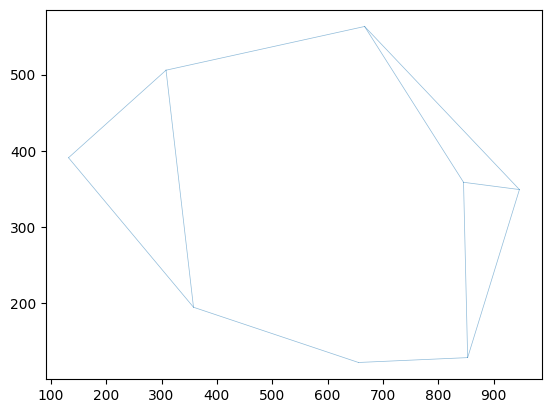

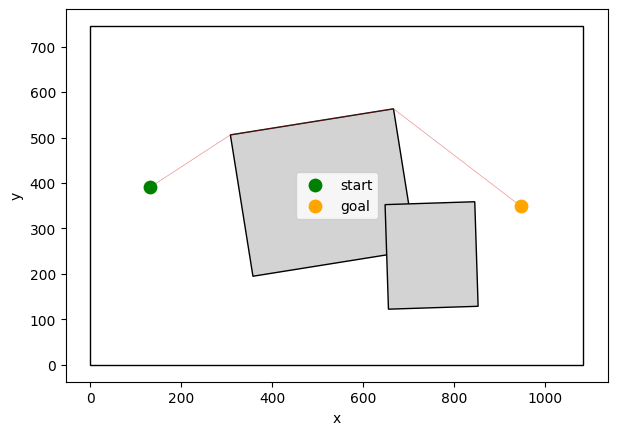

In [8]:
raw_obstacles = get_obstacles_pose()[1:]

start = tuple(get_current_thymio_pose()[:2])
goal = tuple(get_goal_pose())

path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

v = 100
x = get_current_thymio_pose()[2:]
prev_heading = x[0]
print(prev_heading)

In [13]:
for i in range(len(path)-1):
    distance, heading, prev_heading = compute_heading(coords[i], coords[i+1], prev_heading)
    print(distance, heading, prev_heading)
    await turn(v, heading)
    await forward(v, distance)

210.3320820047631 1.2304210117491596 0.5775846197800968
363.40965138481926 -0.41912245665273673 0.15846216312736003
352.1944783751781 -0.8112985550964229 -0.6528363919690628


In [7]:
print(get_goal_pose())

[946.77, 349.2]


In [14]:
await node.unlock()

<br>
<br>
<br>

# testing kalman filter

<br>
<br>
<br>

In [ ]:
initialize_vision(True)